# Лабораторна 5. Донавчання моделей

Відбір заголовків для особистого дайджесту.

In [1]:
# Встановлюємо залежності в Python поточного ядра.
import importlib.util
import subprocess
import sys
packages = {"torch": "torch", "transformers": "transformers==4.57.6", "sklearn": "scikit-learn",
            "pandas": "pandas", "matplotlib": "matplotlib", "onnx": "onnx", "onnxruntime": "onnxruntime", "psutil": "psutil", "setfit": "setfit==1.1.3", "sentence_transformers": "sentence-transformers==5.1.2"}
missing = [requirement for module, requirement in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import gc
import hashlib
import os
import random
import time
from collections import Counter
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, set_seed
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT / "lab5/data").exists():
    ROOT = ROOT / "lab5"
ARTIFACTS = ROOT / "artifacts"
RESULTS = ROOT / "results" / "minilm"
ARTIFACTS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
torch.set_num_threads(4)
SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MAX_LENGTH = 96
print("Пристрій", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Пристрій cuda NVIDIA GeForce RTX 5070


### 1.1. Задача

Опишіть задачу й те, як її результат використовуватиметься на практиці: хто користувач, що подається на вхід і що має бути на виході. Поясніть, чому для неї потрібне саме донавчання, а не промпт чи RAG.

Приклади ідей (можна обрати власну):
- класифікація відгуків чи звернень українською мовою за власним переліком категорій;
- витягування полів з оголошень, резюме чи рецептів у JSON заданої схеми;
- перетворення запитів природною мовою на SQL-запити до конкретної бази даних;
- відповіді в заданому стилі чи форматі, наприклад короткі пояснення термінів для школярів;
- виявлення спаму або токсичних коментарів.

Користувач — я. Вхід — заголовок новини, вихід — показати або пропустити. Оцінки зберігаються до запиту дайджесту. Донавчання переносить мої вподобання у ваги компактного класифікатора й скорочує потребу передавати приклади з кожним запитом.

### 1.2. Модель і дані

- **Модель.** Оберіть модель під задачу й обґрунтуйте вибір: base чи instruct, розмір.
- **Дані.** Візьміть готовий датасет (Hugging Face, Kaggle тощо) або зберіть власний. Вкажіть джерело, ліцензію, кількість прикладів і формат. Покажіть кілька прикладів.
- **Поділ.** Розділіть дані на тренувальний, валідаційний і тестовий набори. Тестові приклади не повинні потрапляти в тренування.

Multilingual MiniLM-L12-v2, близько 118 млн параметрів. Донавчання SetFit і логістична голова на 2 класи. Дані — власний експорт заголовків, збережені ШІ-оцінки та ручні оцінки. Ліцензія моделі Apache-2.0. Окремої ліцензії на новинні заголовки в експорті немає. news та important об’єднано в «показати».

In [2]:
def read_rows(name):
    """Читає повні записи, зберігаючи походження, групу події й людські коментарі."""
    return [json.loads(line) for line in (ROOT / "data" / name).read_text(encoding="utf-8").splitlines() if line.strip()]

ai_train = read_rows("train.jsonl")
ai_val = read_rows("validation.jsonl")
human = read_rows("test.jsonl")
for row in ai_train + ai_val + human:
    row["target"] = int(row["is_relevant"])

# Беремо той самий поділ, що й у першому експерименті DistilBERT.
manifest = json.loads((ROOT / "results/split_ids.json").read_text(encoding="utf-8"))
by_id = {row["sample_id"]: row for row in ai_train + ai_val + human}
experiments = {name: {part: [by_id[sample_id] for sample_id in ids] for part, ids in parts.items()}
               for name, parts in manifest.items()}
human_train = experiments["human"]["train"]
human_val = experiments["human"]["validation"]
human_test = experiments["human"]["test"]
for name, parts in experiments.items():
    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
        a, b = parts[left], parts[right]
        for key in ("group_id", "canonical_url"):
            assert not ({row[key] for row in a} & {row[key] for row in b}), (name, key)
        normalize = lambda text: " ".join(text.casefold().split())
        assert not ({normalize(row["text"]) for row in a} & {normalize(row["text"]) for row in b})
split_manifest = {name: {part: [row["sample_id"] for row in rows] for part, rows in parts.items()} for name, parts in experiments.items()}
(RESULTS / "split_ids.json").write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")
display(pd.DataFrame([{ "experiment": name, "split": part, "rows": len(rows),
                       "unique_urls": len({row["canonical_url"] for row in rows}),
                       "show": sum(row["target"] for row in rows)}
                      for name, parts in experiments.items() for part, rows in parts.items()]))
display(pd.DataFrame(human_train)[["text", "target", "comment"]].head(5))

,experiment,split,rows,unique_urls,show
0,ai,train,113,74,83
1,ai,validation,29,18,23
2,ai,test,200,200,65
3,human,train,121,121,39
4,human,validation,39,39,13
5,human,test,40,40,13
6,mixed,train,263,213,145
7,mixed,validation,39,39,13
8,mixed,test,40,40,13


,text,target,comment
0,УДАР ПО КРЫМСКОМУ МОСТУ: ПОЯВИЛИСЬ СПУТНИКОВЫЕ...,1,коли удар тільки стався - новина відносилась б...
1,Рособрнадзор прорабатывает запрет продажи микр...,0,
2,"Трамп заявляет, что война с Ираном якобы «очен...",0,вже 100 раз він заявляв таке
3,"ОДИН УЖЕ ""МИНУСНУЛИ"": ГЕНШТАБ ДОБАВИЛ МОСТЫ В ...",0,
4,ПОЕЗДА ПОКА КУРСИРУЮТ: ПОЯВИЛОСЬ НОВОЕ ВИДЕО С...,0,


Експеримент ai навчається на ШІ-оцінках і перевіряється на всіх 200 людських. human і mixed мають однаковий відкладений тест. У mixed додано всі ШІ-новини, які не перетинаються з людськими. Для SetFit залишаємо одну мітку на URL — більшість оцінок, за рівності останню за часом. Це не дає повторам переважувати окремі новини. Вчитель раніше бачив частину людських оцінок у промпті.

### 1.3. Модель до донавчання

Оберіть метрику, яка відповідає задачі (accuracy, F1, частка валідних відповідей, точність окремих полів тощо), і поясніть вибір. Оцініть модель на тестовому наборі до донавчання:
- для LLM — з найкращим промптом, який вдасться скласти;
- для класифікатора з новою головою — порівняйте з найпростішим базовим рівнем, наприклад з відповіддю «завжди найчастіший клас».

Наведіть 5–10 прикладів відповідей моделі.

Рахую Macro-F1, precision та recall класу «показати», частку збережених important і матрицю помилок. Високий recall означає, що мало потрібних новин загубилося. Базовий рівень вибирає найчастіший клас тренувальної частини. Також порівнюю зі збереженими прогнозами тієї самої вибірки.

In [3]:
# Попередній прогноз беремо з ручних перевірок, не роблячи нових запитів до LLM.
historical = {}
for path in sorted((ROOT / "data" / "human_sources").glob("*/rated-news.json")):
    for article in json.loads(path.read_text(encoding="utf-8"))["articles"]:
        key = (article["url"], " ".join(article["title"].casefold().split()))
        label = article.get("prediction")
        if label in ("skip", "news", "important", "fun"):
            historical[key] = int(label != "skip")

def metrics(rows, predictions):
    """Порівнює рішення з людськими мітками, включаючи збереження важливих новин."""
    y = np.array([row["target"] for row in rows])
    pred = np.array(predictions, dtype=int)
    important = np.array([row["label_name"] == "important" for row in rows])
    return {"n": len(rows), "accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "show_precision": precision_score(y, pred, zero_division=0), "show_recall": recall_score(y, pred, zero_division=0),
            "important_recall": float(pred[important].mean()) if important.any() else None,
            "missed_relevant": int(((y == 1) & (pred == 0)).sum()), "confusion_matrix": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def old_predictions(rows):
    return [historical[(row["url"], " ".join(row["text"].casefold().split()))] for row in rows]

baselines = {}
for name, parts in experiments.items():
    majority = Counter(row["target"] for row in parts["train"]).most_common(1)[0][0]
    baselines[name] = {"majority": metrics(parts["test"], [majority] * len(parts["test"])),
                       "saved_selection": metrics(parts["test"], old_predictions(parts["test"]))}
display(pd.DataFrame({f"{name}/{method}": values for name, methods in baselines.items() for method, values in methods.items()}).T.drop(columns="confusion_matrix"))
display(pd.DataFrame([{"text": row["text"], "human": row["target"], "saved_prediction": prediction}
                      for row, prediction in zip(human_test[:10], old_predictions(human_test[:10]))]))

,n,accuracy,macro_f1,show_precision,show_recall,important_recall,missed_relevant
ai/majority,200,0.325,0.245283,0.325,1.0,1.0,0
ai/saved_selection,200,0.43,0.429487,0.326241,0.707692,1.0,19
human/majority,40,0.675,0.402985,0.0,0.0,0.0,13
human/saved_selection,40,0.3,0.298246,0.2,0.384615,1.0,8
mixed/majority,40,0.325,0.245283,0.325,1.0,1.0,0
mixed/saved_selection,40,0.3,0.298246,0.2,0.384615,1.0,8


,text,human,saved_prediction
0,КОГДА ПОЯВИТСЯ АНТИБАЛЛИСТИКА ДЛЯ УКРАИНЫ: МИН...,1,1
1,"Суд в Казани не арестовал Юлию Галямину, назна...",0,1
2,"На трасі у Житомирському районі сталася ДТП, р...",0,0
3,"«Если народ скажет “да” Конституции, я не буду...",0,1
4,Grand Theft Auto VI первой в мире стала доступ...,0,1
5,УДАРЫ РФ ПО СЕВЕРНОМУ И ЮЖНОМУ МОСТАМ: ЗЕЛЕНСК...,0,1
6,Госдума одобрила штрафы за «дискредитацию трад...,0,0
7,Генпрокуратура России признала действия сестёр...,0,1
8,По Крымскому мосту зафиксировали два попадания...,0,1
9,"КРЫМСКИЙ МОСТ БЫЛ ПОВТОРНО АТАКОВАН, — МОНИТОРЫ",0,1


### 1.4. Донавчання

Донавчіть модель. Поясніть вибір методу й основних гіперпараметрів: learning rate, кількість кроків чи епох, розмір батча, для LoRA — `r` і `lora_alpha`. Покажіть таблицю чи графік training і validation loss, вкажіть тривалість тренування й пікову памʼять GPU. Якщо помітите перенавчання, поясніть, що змінили.

SetFit донавчає представлення на парах заголовків, потім навчає логістичний класифікатор. Learning rate кістяка 2e-5, batch 16, максимум 80 кроків, довжина 96 токенів. Оцінювання кожні 20 кроків. Найкращий кістяк вибираємо за validation embedding loss. Поріг показу підбираємо лише за валідаційним Macro-F1.

In [4]:
from datasets import Dataset as HFDataset
from setfit import SetFitModel, Trainer as SetFitTrainer, TrainingArguments as SetFitArguments
import copy

def consolidate(rows):
    """Залишає одну мітку на URL, зберігаючи людську оцінку, коли вона є."""
    grouped = {}
    for row in rows:
        grouped.setdefault(row["canonical_url"], []).append(row)
    selected = []
    for versions in grouped.values():
        versions = sorted(versions, key=lambda row: row.get("annotated_at") or "")
        humans = [row for row in versions if row["label_source"] == "human"]
        if humans:
            selected.append(humans[-1])
            continue
        counts = Counter(row["target"] for row in versions)
        majority = max(counts.values())
        selected.append(next(row for row in reversed(versions) if counts[row["target"]] == majority))
    random.Random(SEED).shuffle(selected)
    return selected

def probabilities(model, rows):
    return model.predict_proba([row["text"] for row in rows], as_numpy=True)[:, 1]

def choose_threshold(rows, values):
    """Вибирає поріг за валідацією, за рівності віддає перевагу близькому до 0,5."""
    return float(max(np.linspace(0.1, 0.9, 17),
                 key=lambda threshold: (metrics(rows, values >= threshold)["macro_f1"], -abs(threshold - 0.5))))

def fit_minilm(name, parts):
    """Порівнює заморожену MiniLM з донавченою SetFit на тому самому поділі."""
    set_seed(SEED)
    train_rows, val_rows = consolidate(parts["train"]), consolidate(parts["validation"])
    train_text = [row["text"] for row in train_rows]
    train_labels = [row["target"] for row in train_rows]
    model = SetFitModel.from_pretrained(MODEL_ID, device=DEVICE,
             head_params={"class_weight": "balanced", "random_state": SEED, "max_iter": 1000})
    model.model_body.max_seq_length = MAX_LENGTH
    # Базовий рівень навчає лише голову на готових представленнях MiniLM.
    model.fit(train_text, train_labels, num_epochs=1, batch_size=16, show_progress_bar=False)
    before_threshold = choose_threshold(val_rows, probabilities(model, val_rows))
    before = metrics(human_test, probabilities(model, human_test) >= before_threshold)
    directory = ARTIFACTS / f"minilm_{name}"
    args = SetFitArguments(output_dir=str(directory / "checkpoints"), batch_size=16,
             num_epochs=1, max_steps=80, num_iterations=10, body_learning_rate=2e-5,
             max_length=MAX_LENGTH, eval_strategy="steps", eval_steps=20, eval_max_steps=20,
             save_strategy="steps", save_steps=20, save_total_limit=1, load_best_model_at_end=True,
             metric_for_best_model="embedding_loss", logging_steps=20, report_to="none", seed=SEED)
    make_dataset = lambda rows: HFDataset.from_dict({"text": [row["text"] for row in rows], "label": [row["target"] for row in rows]})
    trainer = SetFitTrainer(model=model, args=args, train_dataset=make_dataset(train_rows), eval_dataset=make_dataset(val_rows))
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    threshold = choose_threshold(val_rows, probabilities(model, val_rows))
    values = probabilities(model, parts["test"])
    common_values = probabilities(model, human_test)
    prediction = (values >= threshold).astype(int)
    result = {"train_unique": len(train_rows), "validation_unique": len(val_rows), "threshold": threshold,
              "before_threshold": before_threshold, "before": before, "training_s": elapsed,
              "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else None,
              "history": trainer.st_trainer.state.log_history,
              "best_checkpoint": trainer.st_trainer.state.best_model_checkpoint,
              "validation": metrics(val_rows, probabilities(model, val_rows) >= threshold),
              "common_test": metrics(human_test, common_values >= threshold),
              "test": metrics(parts["test"], prediction),
              "test_non_duplicate": metrics([row for row in parts["test"] if not row["duplicate"]],
                                             prediction[[not row["duplicate"] for row in parts["test"]]])}
    details = [{"sample_id": row["sample_id"], "text": row["text"], "target": row["target"], "prediction": int(pred),
                "probability": float(probability), "saved_prediction": old, "duplicate": row["duplicate"], "comment": row["comment"]}
               for row, pred, probability, old in zip(parts["test"], prediction, values, old_predictions(parts["test"]))]
    model.save_pretrained(str(directory / "model"))
    (RESULTS / f"{name}.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    (RESULTS / f"{name}_predictions.json").write_text(json.dumps(details, ensure_ascii=False, indent=2), encoding="utf-8")
    del trainer, model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return result

results = {}

In [5]:
results["ai"] = fit_minilm("ai", experiments["ai"])
display(pd.Series(results["ai"]["common_test"]))

model_head.pkl not found on HuggingFace Hub, initialising classification head with random weights. You should TRAIN this model on a downstream task to use it for predictions and inference.


Map:   0%|          | 0/74 [00:00<?, ? examples/s]

Map: 100%|██████████| 74/74 [00:00<00:00, 28326.96 examples/s]


***** Running training *****


  Num unique pairs = 1480


  Batch size = 16


... (4 outputs left out)

D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


The tokenizer you are loading from 'D:\HomeWork\4 курс\сші\lab5\artifacts\minilm_ai\checkpoints\checkpoint-20' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


n                                    40
accuracy                           0.55
macro_f1                       0.548872
show_precision                 0.413793
show_recall                    0.923077
important_recall                    1.0
missed_relevant                       1
confusion_matrix    [[10, 17], [1, 12]]
dtype: object

In [6]:
results["human"] = fit_minilm("human", experiments["human"])
display(pd.Series(results["human"]["common_test"]))

model_head.pkl not found on HuggingFace Hub, initialising classification head with random weights. You should TRAIN this model on a downstream task to use it for predictions and inference.


Map:   0%|          | 0/121 [00:00<?, ? examples/s]

Map: 100%|██████████| 121/121 [00:00<00:00, 39102.46 examples/s]


***** Running training *****


  Num unique pairs = 2420


  Batch size = 16


... (4 outputs left out)

D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


The tokenizer you are loading from 'D:\HomeWork\4 курс\сші\lab5\artifacts\minilm_human\checkpoints\checkpoint-80' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


n                                   40
accuracy                          0.55
macro_f1                      0.354839
show_precision                     0.0
show_recall                        0.0
important_recall                   0.0
missed_relevant                     13
confusion_matrix    [[22, 5], [13, 0]]
dtype: object

In [7]:
results["mixed"] = fit_minilm("mixed", experiments["mixed"])
display(pd.Series(results["mixed"]["common_test"]))

model_head.pkl not found on HuggingFace Hub, initialising classification head with random weights. You should TRAIN this model on a downstream task to use it for predictions and inference.


Map:   0%|          | 0/213 [00:00<?, ? examples/s]

Map: 100%|██████████| 213/213 [00:00<00:00, 56471.98 examples/s]


***** Running training *****


  Num unique pairs = 4260


  Batch size = 16


... (4 outputs left out)

D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


The tokenizer you are loading from 'D:\HomeWork\4 курс\сші\lab5\artifacts\minilm_mixed\checkpoints\checkpoint-60' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


n                                   40
accuracy                           0.6
macro_f1                      0.426523
show_precision                     0.2
show_recall                   0.076923
important_recall                   0.0
missed_relevant                     12
confusion_matrix    [[23, 4], [12, 1]]
dtype: object

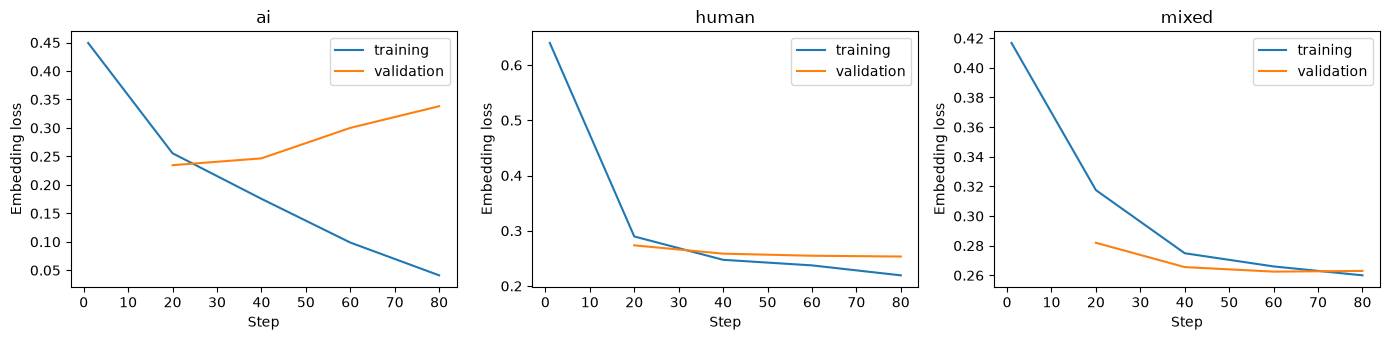

,training_s,peak_gpu_gb,threshold,train_unique
ai,11.513217,2.304103,0.60,74.0
human,11.431157,2.298087,0.75,121.0
mixed,11.363663,2.304314,0.70,213.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for axis, (name, result) in zip(axes, results.items()):
    history = result["history"]
    train = [row for row in history if "embedding_loss" in row]
    validation = [row for row in history if "eval_embedding_loss" in row]
    axis.plot([row["step"] for row in train], [row["embedding_loss"] for row in train], label="training")
    axis.plot([row["step"] for row in validation], [row["eval_embedding_loss"] for row in validation], label="validation")
    axis.set(title=name, xlabel="Step", ylabel="Embedding loss")
    axis.legend()
plt.tight_layout()
plt.savefig(RESULTS / "loss.png", dpi=150)
plt.show()
display(pd.DataFrame({name: {key: result[key] for key in ("training_s", "peak_gpu_gb", "threshold", "train_unique")}
                      for name, result in results.items()}).T)

### 1.5. Порівняння

На тому самому тестовому наборі й тих самих прикладах порівняйте модель до і після донавчання. Проаналізуйте помилки донавченої моделі: які приклади вона розвʼязує неправильно і чому. Для LLM перевірте також на кількох загальних запитах поза вашою задачею, чи не погіршилися відповіді моделі.

In [9]:
comparison = {"saved_selection": metrics(human_test, old_predictions(human_test))}
for name, result in results.items():
    comparison[f"minilm_{name}_before"] = result["before"]
    comparison[f"minilm_{name}_after"] = result["common_test"]
    distilbert = json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
    comparison[f"distilbert_{name}"] = distilbert["common_test"]
display(pd.DataFrame(comparison).T.drop(columns="confusion_matrix"))
(RESULTS / "comparison.json").write_text(json.dumps(comparison, indent=2), encoding="utf-8")
for name in results:
    rows = json.loads((RESULTS / f"{name}_predictions.json").read_text(encoding="utf-8"))
    common_ids = {row["sample_id"] for row in human_test}
    rows = [row for row in rows if row["sample_id"] in common_ids]
    print(name, "приклади")
    display(pd.DataFrame(rows).head(10))
    print(name, "помилки")
    display(pd.DataFrame([row for row in rows if row["target"] != row["prediction"]]).head(10))

,n,accuracy,macro_f1,show_precision,show_recall,important_recall,missed_relevant
saved_selection,40,0.3,0.298246,0.2,0.384615,1.0,8
minilm_ai_before,40,0.6,0.598997,0.44,0.846154,0.666667,2
minilm_ai_after,40,0.55,0.548872,0.413793,0.923077,1.0,1
distilbert_ai,40,0.45,0.43734,0.363636,0.923077,1.0,1
minilm_human_before,40,0.6,0.426523,0.2,0.076923,0.0,12
minilm_human_after,40,0.55,0.354839,0.0,0.0,0.0,13
distilbert_human,40,0.5,0.488491,0.333333,0.538462,0.0,6
minilm_mixed_before,40,0.6,0.466667,0.285714,0.153846,0.0,11
minilm_mixed_after,40,0.6,0.426523,0.2,0.076923,0.0,12
distilbert_mixed,40,0.5,0.404762,0.181818,0.153846,0.0,11


ai приклади


,sample_id,text,target,prediction,probability,saved_prediction,duplicate,comment
0,human-news-100-2026-11-19-d591bcf4b9b44a5c9693...,КНДР опубликовала новую конституцию без упомин...,0,1,0.758693,1,False,
1,human-news-100-2026-11-19-e911b57e0a3233ae1b5b...,"По сообщению читателя Ateo Breaking, над Кишин...",0,1,0.643867,1,False,
2,human-news-100-2026-11-19-61f030425c0be4bb69da...,"""УДАРАМИ ПО КРЫМСКОМУ МОСТУ ИЗОЛИРОВАТЬ ПОЛУОС...",0,1,0.810424,1,False,
3,human-news-100-2026-11-19-96d81a9bb06c02d69c6e...,У Житомирі збираються запровадити послугу «тим...,1,1,0.668618,1,False,
4,human-news-100-2026-11-19-b168bf5e49bd6feb5718...,На саммит РФ — США — КНР отводится час,0,1,0.940762,1,False,
5,human-news-100-2026-11-19-de26017a7f2d7b96bc25...,РОССИЯ ГОТОВИТ НОВЫЙ УДАР ПО ЭНЕРГЕТИКЕ УКРАИН...,1,1,0.911572,1,False,
6,human-news-100-2026-11-19-d087bdd1dd142b8caa36...,Викрили директора ДЮСШ міста Житомирської обла...,0,1,0.713593,1,False,
7,human-news-100-2026-11-19-b8468cd9259f4e16c7c0...,Один из крупнейших российских хостинг-провайде...,0,1,0.647638,1,False,
8,human-news-100-2026-11-19-ee52527622119117d4d7...,КРЫМСКИЙ МОСТ ВТОРОЙ РАЗ ЗА СУТКИ ПОДВЕРГСЯ АТ...,1,1,0.964001,1,True,
9,human-news-100-2026-11-19-7247ed6b7c2bb0e37960...,МВД России объявило в федеральный розыск журна...,0,1,0.880657,1,False,


ai помилки


,sample_id,text,target,prediction,probability,saved_prediction,duplicate,comment
0,human-news-100-2026-11-19-d591bcf4b9b44a5c9693...,КНДР опубликовала новую конституцию без упомин...,0,1,0.758693,1,False,
1,human-news-100-2026-11-19-e911b57e0a3233ae1b5b...,"По сообщению читателя Ateo Breaking, над Кишин...",0,1,0.643867,1,False,
2,human-news-100-2026-11-19-61f030425c0be4bb69da...,"""УДАРАМИ ПО КРЫМСКОМУ МОСТУ ИЗОЛИРОВАТЬ ПОЛУОС...",0,1,0.810424,1,False,
3,human-news-100-2026-11-19-b168bf5e49bd6feb5718...,На саммит РФ — США — КНР отводится час,0,1,0.940762,1,False,
4,human-news-100-2026-11-19-d087bdd1dd142b8caa36...,Викрили директора ДЮСШ міста Житомирської обла...,0,1,0.713593,1,False,
5,human-news-100-2026-11-19-b8468cd9259f4e16c7c0...,Один из крупнейших российских хостинг-провайде...,0,1,0.647638,1,False,
6,human-news-100-2026-11-19-7247ed6b7c2bb0e37960...,МВД России объявило в федеральный розыск журна...,0,1,0.880657,1,False,
7,human-news-100-2026-11-19-b114f2ab252aa7672686...,РФ ПОДГОТОВИЛАСЬ К НОВОМУ РАКЕТНОМУ УДАРУ: ЗЕЛ...,0,1,0.909114,1,False,
8,human-news-100-2026-11-19-c1e5f27a3db8a6b4b942...,Молдова. Пролет дрона над столичным районом Ры...,0,1,0.914731,1,False,
9,human-news-100-2026-11-19-d4074512e21148971440...,На неосвітленій дорозі у Житомирській області ...,0,1,0.804782,1,False,


human приклади


... (3 outputs left out)

mixed приклади


,sample_id,text,target,prediction,probability,saved_prediction,duplicate,comment
0,human-news-100-2026-11-19-04ac4d80d9023993caef...,КОГДА ПОЯВИТСЯ АНТИБАЛЛИСТИКА ДЛЯ УКРАИНЫ: МИН...,1,0,0.477825,1,False,балістика постійна проблема для населення укра...
1,human-news-100-2026-11-19-0625385a9bbb25c3e34f...,"Суд в Казани не арестовал Юлию Галямину, назна...",0,1,0.927918,1,False,не знаю хто така юлия галямин і тим більше мен...
2,human-news-round2-50-2026-11-19-48b02721dd7cd1...,"На трасі у Житомирському районі сталася ДТП, р...",0,0,0.206953,0,False,
3,human-news-round3-50-2026-11-19-9a293365a9d299...,"«Если народ скажет “да” Конституции, я не буду...",0,0,0.556845,1,False,
4,human-news-100-2026-11-19-25c40d00952d263a1ab9...,Grand Theft Auto VI первой в мире стала доступ...,0,0,0.131215,1,False,
5,human-news-100-2026-11-19-27b556939e19958546dd...,УДАРЫ РФ ПО СЕВЕРНОМУ И ЮЖНОМУ МОСТАМ: ЗЕЛЕНСК...,0,0,0.340070,1,False,
6,human-news-round3-50-2026-11-19-06710184dee0cd...,Госдума одобрила штрафы за «дискредитацию трад...,0,0,0.601494,0,False,
7,human-news-round2-50-2026-11-19-292e24f48d1483...,Генпрокуратура России признала действия сестёр...,0,0,0.477003,1,False,
8,human-news-round2-50-2026-11-19-8cef07aa682d39...,По Крымскому мосту зафиксировали два попадания...,0,0,0.590356,1,True,
9,human-news-round3-50-2026-11-19-062baae3b24d5a...,"КРЫМСКИЙ МОСТ БЫЛ ПОВТОРНО АТАКОВАН, — МОНИТОРЫ",0,0,0.393694,1,True,


mixed помилки


,sample_id,text,target,prediction,probability,saved_prediction,duplicate,comment
0,human-news-100-2026-11-19-04ac4d80d9023993caef...,КОГДА ПОЯВИТСЯ АНТИБАЛЛИСТИКА ДЛЯ УКРАИНЫ: МИН...,1,0,0.477825,1,False,балістика постійна проблема для населення укра...
1,human-news-100-2026-11-19-0625385a9bbb25c3e34f...,"Суд в Казани не арестовал Юлию Галямину, назна...",0,1,0.927918,1,False,не знаю хто така юлия галямин і тим більше мен...
2,human-news-round2-50-2026-11-19-b00b26bb3a308b...,Инфляцию в России не удалось снизить до 4% в 2...,1,0,0.591629,0,False,
3,human-news-100-2026-11-19-61f030425c0be4bb69da...,"""УДАРАМИ ПО КРЫМСКОМУ МОСТУ ИЗОЛИРОВАТЬ ПОЛУОС...",0,1,0.742614,1,False,
4,human-news-round2-50-2026-11-19-0c852115ccf269...,ГЕНШТАБ ВСУ ПОЗДРАВИЛ МОСТ ВАСКО ДА ГАМЫ СО ЗВ...,1,0,0.689506,0,False,
5,human-news-round3-50-2026-11-19-7e7f8dc791a581...,"Крайне важно, чтобы мы сотрудничали в борьбе с...",1,0,0.499084,0,False,
6,human-news-round2-50-2026-11-19-059096990f5a0e...,В Украине GTA 6 стало доступно для запуска,1,0,0.416712,0,False,
7,human-news-round3-50-2026-11-19-03648a1088aeb8...,Глава Instagram Адам Моссери сообщил о возможн...,0,1,0.904243,0,False,
8,human-news-100-2026-11-19-96d81a9bb06c02d69c6e...,У Житомирі збираються запровадити послугу «тим...,1,0,0.199661,1,False,
9,human-news-round2-50-2026-11-19-f51ee3ff96febe...,"Товстолоб та білий амур: понад 2,6 тонни риби ...",1,0,0.059383,0,False,


### Локальний запуск на CPU

In [10]:
import tempfile
import shutil
from onnxruntime.quantization import quantize_dynamic, QuantType
chosen = max(("human", "mixed"), key=lambda name: results[name]["validation"]["macro_f1"])
cpu_dir = ARTIFACTS / "minilm_cpu"
cpu_dir.mkdir(exist_ok=True)
setfit_model = SetFitModel.from_pretrained(str(ARTIFACTS / f"minilm_{chosen}" / "model"), device="cpu")
setfit_model.model_body.max_seq_length = MAX_LENGTH

class ExportClassifier(torch.nn.Module):
    """Об’єднує кістяк MiniLM, pooling і навчену логістичну голову."""
    def __init__(self, model):
        super().__init__()
        self.body = model.model_body
        self.register_buffer("weight", torch.tensor(model.model_head.coef_, dtype=torch.float32))
        self.register_buffer("bias", torch.tensor(model.model_head.intercept_, dtype=torch.float32))
    def forward(self, input_ids, attention_mask):
        embeddings = self.body({"input_ids": input_ids, "attention_mask": attention_mask})["sentence_embedding"]
        score = embeddings @ self.weight.T + self.bias
        return torch.cat((torch.zeros_like(score), score), dim=1)

setfit_model.model_body[0].auto_model.set_attn_implementation("eager")
wrapper = ExportClassifier(setfit_model).eval()
tokenizer = setfit_model.model_body.tokenizer
inputs = tokenizer("Приклад новини", return_tensors="pt")
# ONNX C++-операції у Windows виконуються в тимчасовому ASCII-шляху.
with tempfile.TemporaryDirectory(prefix="lab5_minilm_") as temporary:
    fp32_path = Path(temporary) / "model.onnx"
    quantized_path = Path(temporary) / "model.int8.onnx"
    torch.onnx.export(wrapper, (inputs["input_ids"], inputs["attention_mask"]), str(fp32_path),
             input_names=["input_ids", "attention_mask"], output_names=["logits"],
             dynamic_axes={"input_ids": {0: "batch", 1: "sequence"}, "attention_mask": {0: "batch", 1: "sequence"},
                           "logits": {0: "batch"}}, opset_version=17, dynamo=False)
    quantize_dynamic(str(fp32_path), str(quantized_path), weight_type=QuantType.QInt8,
                     op_types_to_quantize=["MatMul", "Gather"])
    shutil.copy2(quantized_path, cpu_dir / "model.int8.onnx")
tokenizer.save_pretrained(cpu_dir)
(cpu_dir / "inference.json").write_text(json.dumps({"model": f"minilm_{chosen}", "max_length": MAX_LENGTH,
               "threshold": results[chosen]["threshold"]}), encoding="utf-8")
reference = probabilities(setfit_model, human_test)
del wrapper, setfit_model
gc.collect()
input_path = RESULTS / "cpu_titles.json"
input_path.write_text(json.dumps([row["text"] for row in human_test], ensure_ascii=False), encoding="utf-8")
process = subprocess.run([sys.executable, str(ROOT / "predict_news.py"), "--model-dir", str(cpu_dir), "--input-file", str(input_path)],
                         check=True, capture_output=True, text=True, encoding="utf-8")
cpu_stats = json.loads(process.stdout)
cpu_p = np.array([row["probability"] for row in cpu_stats["results"]])
cpu_stats["model"] = chosen
cpu_stats["onnx_mb"] = (cpu_dir / "model.int8.onnx").stat().st_size / 1e6
cpu_stats["max_probability_difference"] = float(np.max(np.abs(reference - cpu_p)))
cpu_stats["decision_changes"] = int(((reference >= results[chosen]["threshold"]) != (cpu_p >= results[chosen]["threshold"])).sum())
cpu_stats["metrics"] = metrics(human_test, [row["show"] for row in cpu_stats["results"]])
cpu_stats["ms_per_title"] = cpu_stats["elapsed_s"] * 1000 / len(human_test)
(RESULTS / "cpu.json").write_text(json.dumps(cpu_stats, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.Series({key: value for key, value in cpu_stats.items() if key not in ("results", "metrics")}))
display(pd.Series(cpu_stats["metrics"]))

The tokenizer you are loading from 'D:\HomeWork\4 курс\сші\lab5\artifacts\minilm_mixed\model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


BertModel does not support setting its attention implementation dynamically, because it does not follow the functional approach based on AttentionInterface (see https://huggingface.co/docs/transformers/en/attention_interface)


C:\Users\Bresh\AppData\Local\Temp\ipykernel_25652\1839817443.py:30: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  torch.onnx.export(wrapper, (inputs["input_ids"], inputs["attention_mask"]), str(fp32_path),
D:\HomeWork\4 курс\сші\lab5\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\utils.py:217: DeprecationWarning: The feature will be removed. Please remove usage of this function
  setup_onnx_logging(verbose) as log_ctx,
D:\HomeWork\4 курс\сші\

elapsed_s                       0.110677
rss_mb                        457.179136
peak_rss_mb                   543.506432
model                              mixed
onnx_mb                       118.185361
max_probability_difference      0.076341
decision_changes                       2
ms_per_title                     2.76692
dtype: object

n                                   40
accuracy                           0.6
macro_f1                      0.426523
show_precision                     0.2
show_recall                   0.076923
important_recall                   0.0
missed_relevant                     12
confusion_matrix    [[23, 4], [12, 1]]
dtype: object

### 1.6. Мій звіт:
- **Задача і чому потрібне донавчання:** ...
- **Модель і дані:** ...
- **Метрика й результат до донавчання:** ...
- **Метод донавчання й гіперпараметри:** ...
- **Результат після донавчання:** ...
- **Аналіз помилок:** ...
- **Висновок:** ...

In [11]:
from IPython.display import Markdown
result = results[chosen]
test = result["common_test"]
old = comparison["saved_selection"]
report = f"""- **Задача і чому потрібне донавчання:** особистий відбір заголовків за прикладами моїх оцінок.
- **Модель і дані:** multilingual MiniLM-L12-v2, близько 118 млн параметрів, SetFit. Три експерименти, спільний тест {len(human_test)} новин. Повторні AI-версії одного URL зведено до більшості міток, за рівності взято останню.
- **Метрика й результат до донавчання:** заморожена MiniLM із навченою головою, Macro-F1 {result['before']['macro_f1']:.3f}. Збережений відбір вибірки — {old['macro_f1']:.3f}.
- **Метод донавчання й гіперпараметри:** SetFit, кістяк lr 2e-5, batch 16, 80 кроків, довжина 96. Голова — логістична регресія з class_weight=balanced. Час {result['training_s']:.1f} с, пік GPU {result['peak_gpu_gb']:.2f} GB. Для експорту обрано {chosen} за людською валідацією.
- **Результат після донавчання:** Macro-F1 {test['macro_f1']:.3f}, precision потрібних {test['show_precision']:.1%}, recall потрібних {test['show_recall']:.1%}, пропущено потрібних {test['missed_relevant']}.
- **Аналіз помилок:** приклади в 1.5. Сам заголовок не містить історії вже прочитаних новин. AI-розмітка частково суперечлива. Тест малий і вже використовувався при порівнянні моделей.
- **Висновок:** зміна Macro-F1 від донавчання {test['macro_f1'] - result['before']['macro_f1']:+.3f}. CPU INT8 — {cpu_stats['ms_per_title']:.1f} мс/заголовок, пікова пам’ять процесу {cpu_stats['peak_rss_mb']:.1f} MB. Це замір на ПК з одним потоком. RAM сервера разом з ботом ще не виміряно.
- **Опублікована модель:** [MiniLM + SetFit — DBresh1/minilm-news-filter](https://huggingface.co/DBresh1/minilm-news-filter).
"""
display(Markdown(report))
(RESULTS / "report.txt").write_text(report, encoding="utf-8")

- **Задача і чому потрібне донавчання:** особистий відбір заголовків за прикладами моїх оцінок.
- **Модель і дані:** multilingual MiniLM-L12-v2, близько 118 млн параметрів, SetFit. Три експерименти, спільний тест 40 новин. Повторні AI-версії одного URL зведено до більшості міток, за рівності взято останню.
- **Метрика й результат до донавчання:** заморожена MiniLM із навченою головою, Macro-F1 0.467. Збережений відбір вибірки — 0.298.
- **Метод донавчання й гіперпараметри:** SetFit, кістяк lr 2e-5, batch 16, 80 кроків, довжина 96. Голова — логістична регресія з class_weight=balanced. Час 11.4 с, пік GPU 2.30 GB. Для експорту обрано mixed за людською валідацією.
- **Результат після донавчання:** Macro-F1 0.427, precision потрібних 20.0%, recall потрібних 7.7%, пропущено потрібних 12.
- **Аналіз помилок:** приклади в 1.5. Сам заголовок не містить історії вже прочитаних новин. AI-розмітка частково суперечлива. Тест малий і вже використовувався при порівнянні моделей.
- **Висновок:** зміна Macro-F1 від донавчання -0.040. CPU INT8 — 2.8 мс/заголовок, пікова пам’ять процесу 543.5 MB. Це замір на ПК з одним потоком. RAM сервера разом з ботом ще не виміряно.
- **Опублікована модель:** [MiniLM + SetFit — DBresh1/minilm-news-filter](https://huggingface.co/DBresh1/minilm-news-filter).


1169